# Phase Recovery With a Reference Laser: Phase-Shifting Interferometry vs Dispersion-Assisted GS

Library: `dgs/phase_shifting.py` (tests: `tests/test_phase_shifting.py`), compared against `dgs/gs_core.py`.

## In plain words

A camera or photodiode records only brightness, $|E|^2$, so the phase is lost. There are two ways to get it back.

* **With a reference (phase-shifting interferometry, PSI).** Add a known laser beam to the signal and take pictures while stepping the reference's phase by a quarter wave each time. The brightness of each pixel goes up and down as a cosine, and the cosine's position *is* the phase. Four pictures and one `atan2` give the answer, with no guessing.
* **Without a reference (this repository).** Send the signal through two different lengths of dispersive fiber and record both intensities. The signal interferes with *itself*, so the measurements depend on the phase nonlinearly, and Gerchberg-Saxton has to iterate.

This notebook recovers **the same phase** both ways at **the same detector noise** and compares accuracy, frame count, and what can go wrong.

In [1]:
import sys, pathlib
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
from dgs import phase_shifting as P
from dgs import gs_core as gs
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. The math: why $N$ equal steps give the phase in one line

Frame $k$ records $I_k = |E + R e^{i\delta_k}|^2 = |E|^2 + R^2 + 2|E|R\cos(\phi-\delta_k)$ with $\delta_k = 2\pi k/N$. Multiply by $e^{i\delta_k}$ and sum. The constant term and the $e^{-i\phi}$ term sum to zero over a full circle (for $N\ge 3$), leaving

$$\sum_{k=0}^{N-1} I_k\, e^{i\delta_k} = N|E|R\,e^{i\phi}.$$

SymPy check for $N = 3, 4, 5$, and the familiar 4-step form $\phi=\mathrm{atan2}(I_1-I_3,\ I_0-I_2)$:

In [2]:
A, Rr, phi = sp.symbols('A R phi', positive=True)
for N in (3, 4, 5):
    deltas = [2*sp.pi*k/N for k in range(N)]
    I = [A**2 + Rr**2 + 2*A*Rr*sp.cos(phi - d) for d in deltas]
    S = sum(Ik*sp.exp(sp.I*d) for Ik, d in zip(I, deltas))
    ok = sp.simplify(sp.expand_complex(S - N*A*Rr*sp.exp(sp.I*phi))) == 0
    print(f'N={N}: sum I_k e^(i delta_k) = N|E|R e^(i phi) ->', ok)
I4 = [A**2 + Rr**2 + 2*A*Rr*sp.cos(phi - k*sp.pi/2) for k in range(4)]
print('I1 - I3 =', sp.simplify(I4[1] - I4[3]), '   I0 - I2 =', sp.simplify(I4[0] - I4[2]))

N=3: sum I_k e^(i delta_k) = N|E|R e^(i phi) -> True
N=4: sum I_k e^(i delta_k) = N|E|R e^(i phi) -> True


N=5: sum I_k e^(i delta_k) = N|E|R e^(i phi) -> True
I1 - I3 = 4*A*R*sin(phi)    I0 - I2 = 4*A*R*cos(phi)


With two steps the sum cannot separate $\cos\phi$ from $\sin\phi$, which is why `phase_steps` rejects $N<3$.

**Noise.** If each frame has Gaussian noise of standard deviation $\sigma$, the sum has noise $\sqrt{N}\sigma$ spread over two quadratures, and the signal is $N|E|R$, so

$$\sigma_\phi \approx \frac{\sigma}{\sqrt{2N}\,|E|R}.$$

## 2. Same phase, same noise, both methods

The test phase is the README's one (`gs_core.make_qpsk_measurements`: 512 samples, smooth band-limited, scaled to $\pm\pi$), at 25 dB SNR. The noise standard deviation is the same absolute value for both methods. GS error is reported after removing the constant offset and sign flip it cannot see; PSI error is raw, because the reference fixes both.

GS  (2 frames, no reference, 60 iterations): 0.061 rad RMS
PSI (4 frames, reference laser, closed form): 0.020 rad RMS (predicted 0.0199)


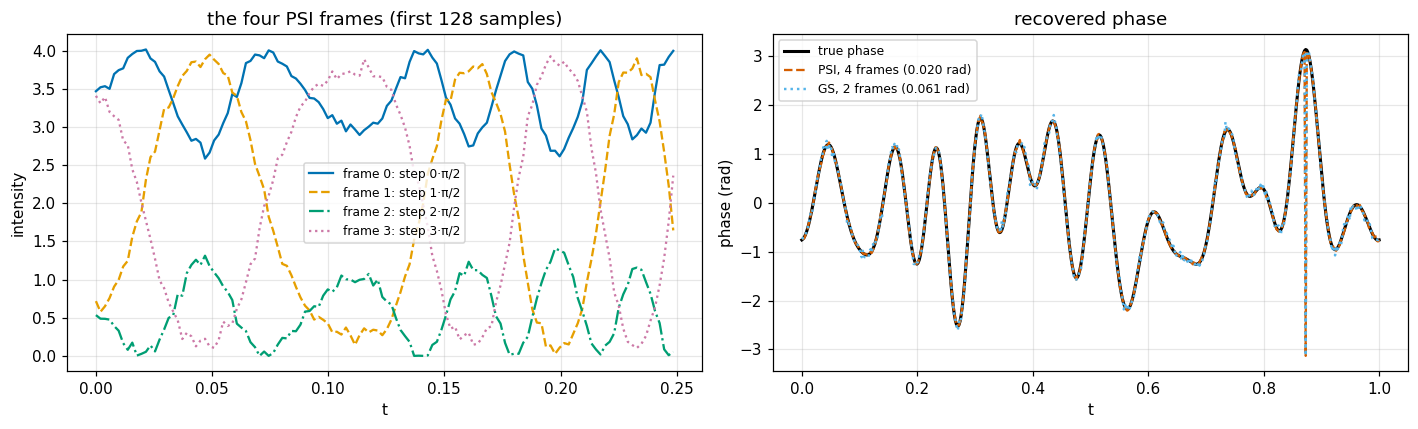

Figure 1. Left: the four simulated PSI frames over the first 128 samples. Each is the signal plus a reference whose phase is stepped by a quarter wave, so the four curves are shifted cosines of the same unknown phase. Right: the true phase (solid black), the PSI recovery (dashed red) and the GS recovery (dotted blue); both lie on top of the true phase at this scale, and the RMS errors in the legend give the difference.


In [3]:
wp = gs.make_qpsk_measurements(snr_db=25.0, rng_seed=0)
t, phi_t = wp['t'], wp['phi_true']
phi_gs, _ = gs.retrieve_phase(wp['I1'], wp['I2'], wp['D1'], wp['D2'], n_iter=60)
best = min(((P.wrapped_rms(s*phi_gs + np.angle(np.sum(np.exp(1j*(phi_t - s*phi_gs)))), phi_t), s) for s in (1, -1)))
s = best[1]; phi_gs_al = np.angle(np.exp(1j*(s*phi_gs + np.angle(np.sum(np.exp(1j*(phi_t - s*phi_gs)))))))
frames = P.psi_frames(np.exp(1j*phi_t), n_steps=4, snr_db=25.0, rng_seed=1)
phi_psi, amp_psi = P.psi_retrieve(frames)
r = P.compare_with_gs(25.0)
print(f"GS  (2 frames, no reference, 60 iterations): {r['gs_rms']:.3f} rad RMS")
print(f"PSI (4 frames, reference laser, closed form): {r['psi_rms']:.3f} rad RMS (predicted {r['psi_predicted']:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, (c, ls) in enumerate(zip([OI['blue'], OI['orange'], OI['green'], OI['purple']], ['-', '--', '-.', ':'])):
    ax[0].plot(t[:128], frames[k, :128], color=c, ls=ls, label=f'frame {k}: step {k}·π/2')
ax[0].set_xlabel('t'); ax[0].set_ylabel('intensity'); ax[0].set_title('the four PSI frames (first 128 samples)'); ax[0].legend(fontsize=8)
ax[1].plot(t, phi_t, color=OI['black'], lw=2, ls='-', label='true phase')
ax[1].plot(t, phi_psi, color=OI['red'], ls='--', label=f"PSI, 4 frames ({r['psi_rms']:.3f} rad)")
ax[1].plot(t, phi_gs_al, color=OI['sky'], ls=':', lw=1.6, label=f"GS, 2 frames ({r['gs_rms']:.3f} rad)")
ax[1].set_xlabel('t'); ax[1].set_ylabel('phase (rad)'); ax[1].set_title('recovered phase'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 1. Left: the four simulated PSI frames over the first 128 samples. Each is the signal plus a reference whose phase '
      'is stepped by a quarter wave, so the four curves are shifted cosines of the same unknown phase. Right: the true phase (solid black), '
      'the PSI recovery (dashed red) and the GS recovery (dotted blue); both lie on top of the true phase at this scale, and the RMS '
      'errors in the legend give the difference.')

## 3. Error versus noise

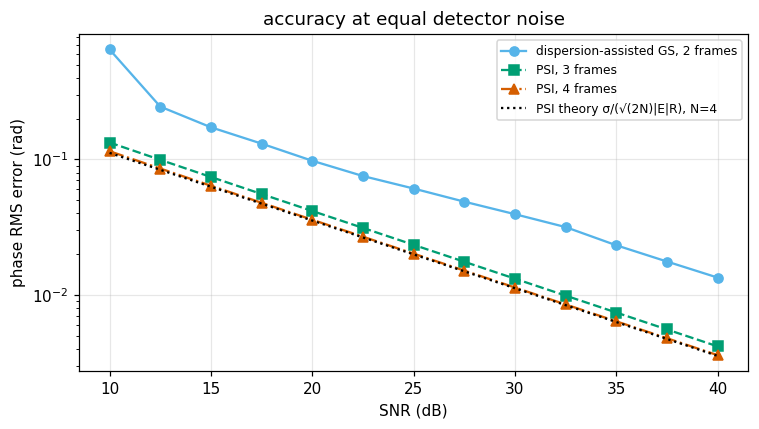

Figure 2. Phase error versus SNR on a log scale. PSI with 4 frames (dash-dot red) follows the theory line (dotted black) at every SNR; 3 frames (dashed green) is slightly worse. GS with 2 frames (solid blue) is 2.7-3.7x worse than 4-step PSI from 12.5 to 40 dB; at 10 dB GS breaks down (0.65 rad, 5.6x) while PSI degrades smoothly.


In [4]:
snrs = np.arange(10, 41, 2.5)
rows = [P.compare_with_gs(float(x)) for x in snrs]
gs_e = np.array([q['gs_rms'] for q in rows]); psi4 = np.array([q['psi_rms'] for q in rows])
psi3 = np.array([P.compare_with_gs(float(x), n_steps=3)['psi_rms'] for x in snrs])
pred4 = np.array([P.predicted_phase_rms(x, 4) for x in snrs])
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(snrs, gs_e, color=OI['sky'], ls='-', marker='o', label='dispersion-assisted GS, 2 frames')
ax.semilogy(snrs, psi3, color=OI['green'], ls='--', marker='s', label='PSI, 3 frames')
ax.semilogy(snrs, psi4, color=OI['red'], ls='-.', marker='^', label='PSI, 4 frames')
ax.semilogy(snrs, pred4, color=OI['black'], ls=':', label='PSI theory σ/(√(2N)|E|R), N=4')
ax.set_xlabel('SNR (dB)'); ax.set_ylabel('phase RMS error (rad)'); ax.set_title('accuracy at equal detector noise'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f'Figure 2. Phase error versus SNR on a log scale. PSI with 4 frames (dash-dot red) follows the theory line (dotted black) '
      f'at every SNR; 3 frames (dashed green) is slightly worse. GS with 2 frames (solid blue) is '
      f'{(gs_e/psi4)[1:].min():.1f}-{(gs_e/psi4)[1:].max():.1f}x worse than 4-step PSI from {snrs[1]:.1f} to {snrs[-1]:.0f} dB; '
      f'at {snrs[0]:.0f} dB GS breaks down ({gs_e[0]:.2f} rad, {gs_e[0]/psi4[0]:.1f}x) while PSI degrades smoothly.')

Part of the gap is just more light: PSI collects 4 frames plus a reference beam, GS 2 frames and nothing else. The other part is the nonlinearity: GS has to iterate on a problem with no closed form.

## 4. What goes wrong with a reference: phase-step miscalibration

The classic PSI error is a piezo whose stroke is slightly off, so every step is $(1+\epsilon/(\pi/2))$ times too long. The error is mostly a **constant offset** (harmless, like the one GS cannot see) plus a **ripple at twice the phase frequency with peak $\approx\epsilon/2$**:

eps=0.02: constant offset -0.0305 rad, ripple peak 0.0105 rad, eps/2 = 0.0100
eps=0.05: constant offset -0.0762 rad, ripple peak 0.0262 rad, eps/2 = 0.0250
eps=0.1: constant offset -0.1518 rad, ripple peak 0.0519 rad, eps/2 = 0.0500
eps=0.2: constant offset -0.3018 rad, ripple peak 0.1023 rad, eps/2 = 0.1000


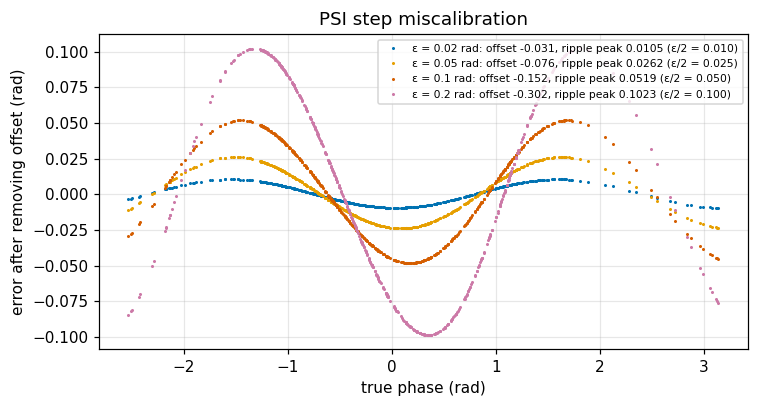

Figure 3. PSI phase error (after removing the constant offset) against the true phase, for four step errors; each is a different colour and marker density. The error is a ripple that repeats twice per 2π of phase, and its peak grows as ε/2, so a 0.1 rad step error leaves ~0.05 rad of ripple, comparable to the whole GS error at 25 dB.


In [5]:
eps_list = [0.02, 0.05, 0.1, 0.2]
fig, ax = plt.subplots(figsize=(7, 3.8))
for eps, c, ls in zip(eps_list, [OI['blue'], OI['orange'], OI['red'], OI['purple']], ['-', '--', '-.', ':']):
    ph = P.psi_retrieve(P.psi_frames(np.exp(1j*phi_t), step_error_rad=eps))[0]
    d = np.angle(np.exp(1j*(ph - phi_t))); off = np.angle(np.mean(np.exp(1j*d)))
    rip = np.angle(np.exp(1j*(d - off)))
    ax.plot(phi_t, rip, '.', ms=2, color=c, label=f'ε = {eps} rad: offset {off:+.3f}, ripple peak {np.abs(rip).max():.4f} (ε/2 = {eps/2:.3f})')
    print(f'eps={eps}: constant offset {off:+.4f} rad, ripple peak {np.abs(rip).max():.4f} rad, eps/2 = {eps/2:.4f}')
ax.set_xlabel('true phase (rad)'); ax.set_ylabel('error after removing offset (rad)'); ax.set_title('PSI step miscalibration'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print('Figure 3. PSI phase error (after removing the constant offset) against the true phase, for four step errors; each is a '
      'different colour and marker density. The error is a ripple that repeats twice per 2π of phase, and its peak grows as ε/2, '
      'so a 0.1 rad step error leaves ~0.05 rad of ripple, comparable to the whole GS error at 25 dB.')

## 5. Side by side

| | PSI (reference laser) | dispersion-assisted GS (this repository) |
|---|---|---|
| extra hardware | coherent reference arm + phase stepper (piezo), stable to a fraction of a wavelength | two dispersive fibers (or one, measured twice) |
| frames | $N\ge 3$ (4 here) | 2 for smooth phases; up to 5 for QPSK data |
| solve | one closed-form step, $\phi=\arg\sum I_k e^{i\delta_k}$ | iterative projections (60 iterations here) |
| ambiguities | none (the reference sets the absolute phase) | constant offset and sign flip |
| 25 dB, same noise | **0.020 rad** | **0.061 rad** |
| main error source | step miscalibration, vibration between frames | low diversity (small $\lvert D\rvert$), stagnation |
| where it is used | lens and wafer testing, holography, optical coherence tomography | single-shot ultrafast measurement, reference-free optical receivers |

PSI wins on accuracy and simplicity *if* you can afford a stable reference. Dispersion-assisted GS exists for the cases where you cannot: a carrier-free receiver, or a pulse too fast to step a reference across.

**Limitations.** Gaussian detector noise only (no shot noise, no vibration between frames); perfect fringe contrast and a reference of uniform amplitude; one test phase and one noise seed per point.

**References** (from memory; verify before citing)

[1] J. H. Bruning, D. R. Herriott, J. E. Gallagher, D. P. Rosenfeld, A. D. White, and D. J. Brangaccio, "Digital wavefront measuring interferometer for testing optical surfaces and lenses," *Appl. Opt.*, vol. 13, no. 11, pp. 2693–2703, 1974.

[2] K. Creath, "Phase-measurement interferometry techniques," in *Progress in Optics*, vol. 26, E. Wolf, Ed. Amsterdam: Elsevier, 1988, pp. 349–393.

[3] P. Hariharan, B. F. Oreb, and T. Eiju, "Digital phase-shifting interferometry: a simple error-compensating phase calculation algorithm," *Appl. Opt.*, vol. 26, no. 13, pp. 2504–2506, 1987.

[4] D. R. Solli, S. Gupta, and B. Jalali, "Optical phase recovery in the dispersive Fourier transform," *Appl. Phys. Lett.*, vol. 95, no. 23, Art. no. 231108, 2009.